# Checkpoint: the brief's required experiment

This notebook reproduces every number in the report's experiment section. It calls `experiments/brief_experiment.py`, which uses the same engine as the game.

* **Step 1** payloads: a 4-qubit mirror circuit and T-doped versions (T count 0, 2, 4, 8; T and T-dagger both count).
* **Step 2** reference: StabilizerState (Clifford) cross-checked against Statevector; fidelity = Hellinger fidelity of the data qubits' output.
* **Step 3** checks: qiskit-paulice on the Clifford payload (every check count, four target orders); hand checks obeying the T rule for the T-doped ones.
* **Step 4** noise: three models (game T-series, uniform depolarizing, GenericBackendV2 calibration). No common noise model was announced by the organizers, so these are the models used.
* **Step 5** measure: fidelity without checks, post-selected fidelity, kept-shot fraction, added ancillas, two-qubit gates and depth.
* **Step 6** compare: best trade-off = highest fidelity with yield >= 0.85 (ties: lower cost), plus the Pareto front.

All scores are exact (Aer density matrix, readout applied analytically). Running this notebook twice gives identical numbers.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'experiments' else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT)); sys.path.insert(0, str(ROOT / 'experiments'))
import brief_experiment as bx
models = bx.noise_models()
{k: v.label for k, v in models.items()}

{'series': 'game T-series noise (Z-biased)',
 'uniform': 'uniform depolarizing, p2 = 0.01',
 'backend': 'GenericBackendV2(12 qubits, seed 2026) calibration, layout [0,1,2,3]'}

## Step 1 and 2: payloads and references

In [2]:
for tc in bx.T_SITES:
    lv = bx.payload_level(tc)
    ref = bx.reference_check(lv)
    print(f"T count {tc}: width {lv['n_qubits']}, moments {len(lv['moments'])}, ideal output {ref['statevector']}" + (" (stabilizer reference agrees)" if 'stabilizer' in ref else ''))

T count 0: width 4, moments 10, ideal output {np.str_('0000'): np.float64(1.0)} (stabilizer reference agrees)
T count 2: width 4, moments 10, ideal output {np.str_('0000'): np.float64(1.0)}
T count 4: width 4, moments 10, ideal output {np.str_('0000'): np.float64(1.0)}
T count 8: width 4, moments 10, ideal output {np.str_('0000'): np.float64(1.0)}


## Steps 3 to 6 under each noise model

In [3]:
results = {name: bx.run_one(name, params, ROOT / 'experiments' / 'results' / name) for name, params in models.items()}
for name, r in results.items():
    print(name)
    for t, b in r['best_by_t'].items():
        print(f"  T={t}: no checks F={r['summary']['payloads'][t]['baseline']['fidelity']:.4f} | best F={b['fidelity']:.4f} at yield {b['yield']:.3f}, cost {b['cost']} ({b['method']})")

series
  T=0: no checks F=0.8958 | best F=0.9900 at yield 0.853, cost 6 (hand)
  T=2: no checks F=0.8881 | best F=0.9507 at yield 0.893, cost 5 (hand)
  T=4: no checks F=0.8772 | best F=0.9097 at yield 0.874, cost 6 (hand)
  T=8: no checks F=0.8822 | best F=0.9087 at yield 0.882, cost 6 (hand)
uniform
  T=0: no checks F=0.9073 | best F=0.9827 at yield 0.873, cost 6 (hand)
  T=2: no checks F=0.9028 | best F=0.9681 at yield 0.892, cost 5 (hand)
  T=4: no checks F=0.8966 | best F=0.9520 at yield 0.900, cost 5 (hand)
  T=8: no checks F=0.8984 | best F=0.9526 at yield 0.901, cost 5 (hand)
backend
  T=0: no checks F=0.9730 | best F=0.9966 at yield 0.959, cost 6 (hand)
  T=2: no checks F=0.9659 | best F=0.9901 at yield 0.967, cost 5 (hand)
  T=4: no checks F=0.9554 | best F=0.9820 at yield 0.944, cost 7 (hand)
  T=8: no checks F=0.9619 | best F=0.9837 at yield 0.971, cost 5 (hand)


# Brief experiment: game T-series noise (Z-biased)

Selection rule for the best trade-off: highest post-selected fidelity with yield >= 0.85, ties broken by lower cost.
All numbers are exact (density matrix, readout applied analytically); no shot sampling.

| T count | width | depth | legal single checks | fidelity, no checks | best (rule) fidelity | its yield | its cost | method | Pareto points |
|---|---|---|---|---|---|---|---|---|---|
| 0 | 4 | 6 | 1760 | 0.8958 | 0.9900 | 0.853 | 6 | hand | 17 |
| 2 | 4 | 8 | 1407 | 0.8881 | 0.9507 | 0.893 | 5 | hand | 11 |
| 4 | 4 | 10 | 1186 | 0.8772 | 0.9097 | 0.874 | 6 | hand | 8 |
| 8 | 4 | 10 | 866 | 0.8822 | 0.9087 | 0.882 | 6 | hand | 9 |

## qiskit-paulice on the Clifford payload (T count 0)

| target order | checks | fidelity | yield | cost |
|---|---|---|---|---|
| 0-1-2-3 | 0 | 0.8958 | 1.000 | 0 |
| 0-1-2-3 | 1 | 0.9211 | 0.925 | 3 |
| 0-1-2-3 | 2 | 0.9224 | 0.834 | 7 |
| 0-1-2-3 | 3 | 0.9298 | 0.770 | 11 |
| 0-1-2-3 | 4 | 0.9549 | 0.690 | 14 |
| 3-2-1-0 | 0 | 0.8958 | 1.000 | 0 |
| 3-2-1-0 | 1 | 0.9023 | 0.943 | 3 |
| 3-2-1-0 | 2 | 0.8882 | 0.843 | 7 |
| 3-2-1-0 | 3 | 0.8959 | 0.779 | 11 |
| 3-2-1-0 | 4 | 0.9414 | 0.709 | 14 |
| 1-2-0-3 | 0 | 0.8958 | 1.000 | 0 |
| 1-2-0-3 | 1 | 0.9159 | 0.928 | 3 |
| 1-2-0-3 | 2 | 0.8994 | 0.856 | 7 |
| 1-2-0-3 | 3 | 0.9005 | 0.808 | 11 |
| 1-2-0-3 | 4 | 0.9152 | 0.712 | 14 |
| 2-0-3-1 | 0 | 0.8958 | 1.000 | 0 |
| 2-0-3-1 | 1 | 0.9211 | 0.925 | 3 |
| 2-0-3-1 | 2 | 0.9461 | 0.863 | 6 |
| 2-0-3-1 | 3 | 0.9462 | 0.826 | 9 |
| 2-0-3-1 | 4 | 0.9603 | 0.728 | 13 |


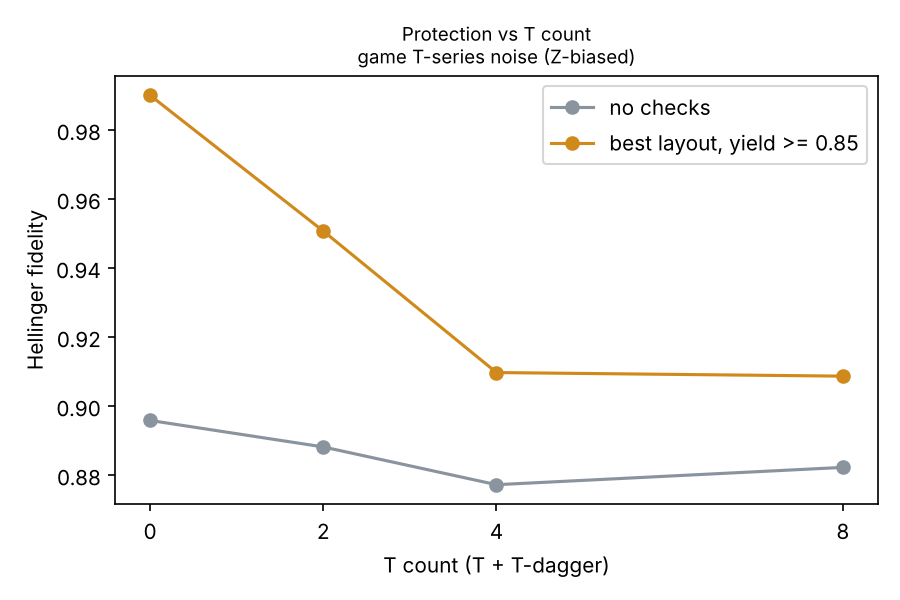

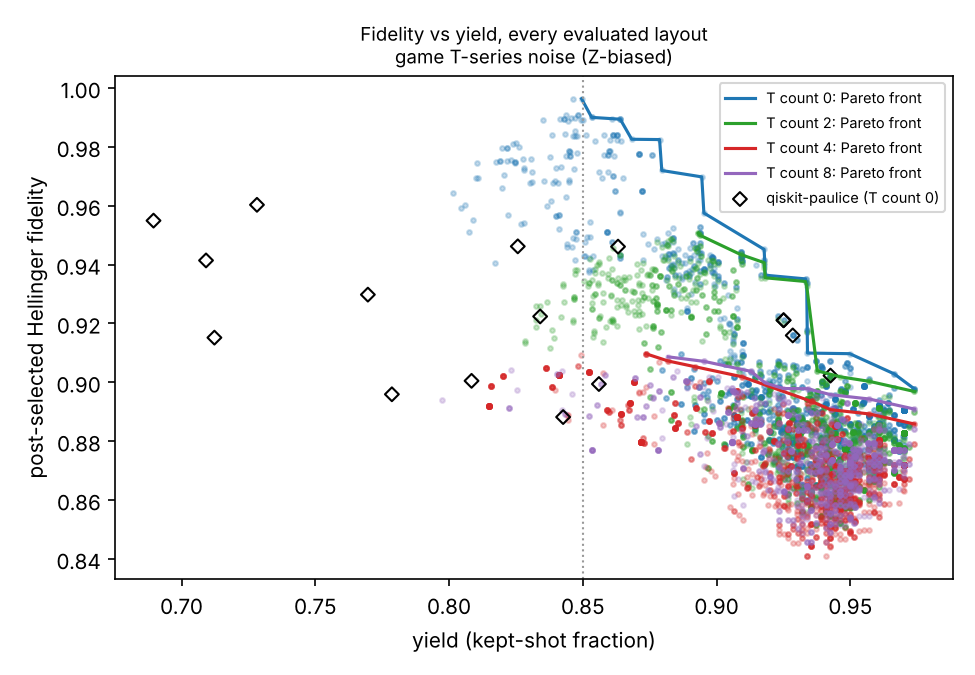

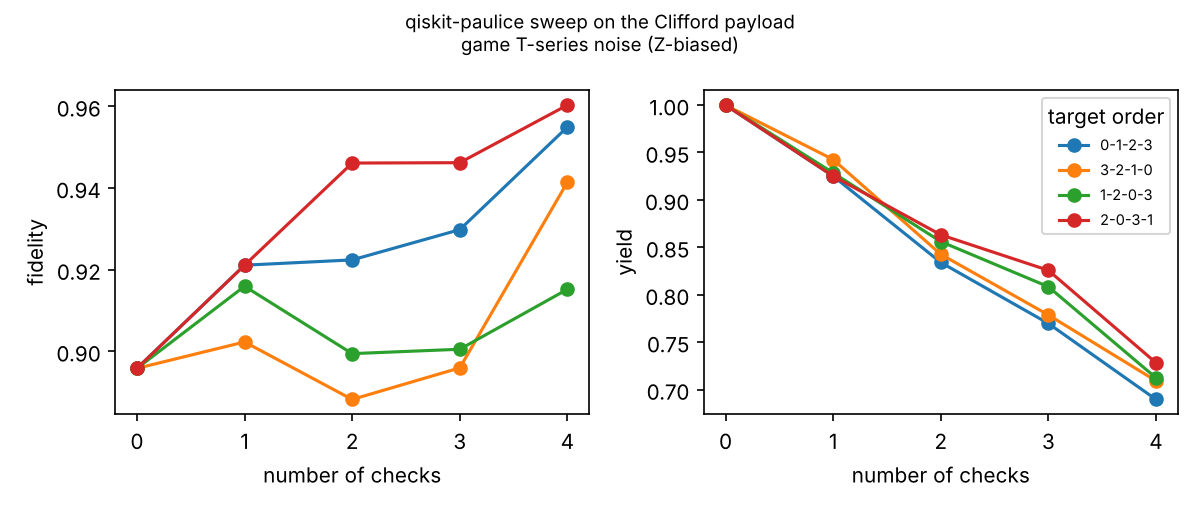

# Brief experiment: uniform depolarizing, p2 = 0.01

Selection rule for the best trade-off: highest post-selected fidelity with yield >= 0.85, ties broken by lower cost.
All numbers are exact (density matrix, readout applied analytically); no shot sampling.

| T count | width | depth | legal single checks | fidelity, no checks | best (rule) fidelity | its yield | its cost | method | Pareto points |
|---|---|---|---|---|---|---|---|---|---|
| 0 | 4 | 6 | 1760 | 0.9073 | 0.9827 | 0.873 | 6 | hand | 26 |
| 2 | 4 | 8 | 1407 | 0.9028 | 0.9681 | 0.892 | 5 | hand | 21 |
| 4 | 4 | 10 | 1186 | 0.8966 | 0.9520 | 0.900 | 5 | hand | 17 |
| 8 | 4 | 10 | 866 | 0.8984 | 0.9526 | 0.901 | 5 | hand | 16 |

## qiskit-paulice on the Clifford payload (T count 0)

| target order | checks | fidelity | yield | cost |
|---|---|---|---|---|
| 0-1-2-3 | 0 | 0.9073 | 1.000 | 0 |
| 0-1-2-3 | 1 | 0.9206 | 0.955 | 3 |
| 0-1-2-3 | 2 | 0.9156 | 0.905 | 7 |
| 0-1-2-3 | 3 | 0.9042 | 0.858 | 11 |
| 0-1-2-3 | 4 | 0.9237 | 0.807 | 14 |
| 3-2-1-0 | 0 | 0.9073 | 1.000 | 0 |
| 3-2-1-0 | 1 | 0.9184 | 0.944 | 3 |
| 3-2-1-0 | 2 | 0.9183 | 0.881 | 7 |
| 3-2-1-0 | 3 | 0.9110 | 0.851 | 10 |
| 3-2-1-0 | 4 | 0.9304 | 0.807 | 13 |
| 1-2-0-3 | 0 | 0.9073 | 1.000 | 0 |
| 1-2-0-3 | 1 | 0.9152 | 0.956 | 3 |
| 1-2-0-3 | 2 | 0.9224 | 0.911 | 6 |
| 1-2-0-3 | 3 | 0.9278 | 0.876 | 9 |
| 1-2-0-3 | 4 | 0.9353 | 0.829 | 12 |
| 2-0-3-1 | 0 | 0.9073 | 1.000 | 0 |
| 2-0-3-1 | 1 | 0.9206 | 0.955 | 3 |
| 2-0-3-1 | 2 | 0.9332 | 0.917 | 6 |
| 2-0-3-1 | 3 | 0.9304 | 0.891 | 9 |
| 2-0-3-1 | 4 | 0.9370 | 0.844 | 12 |


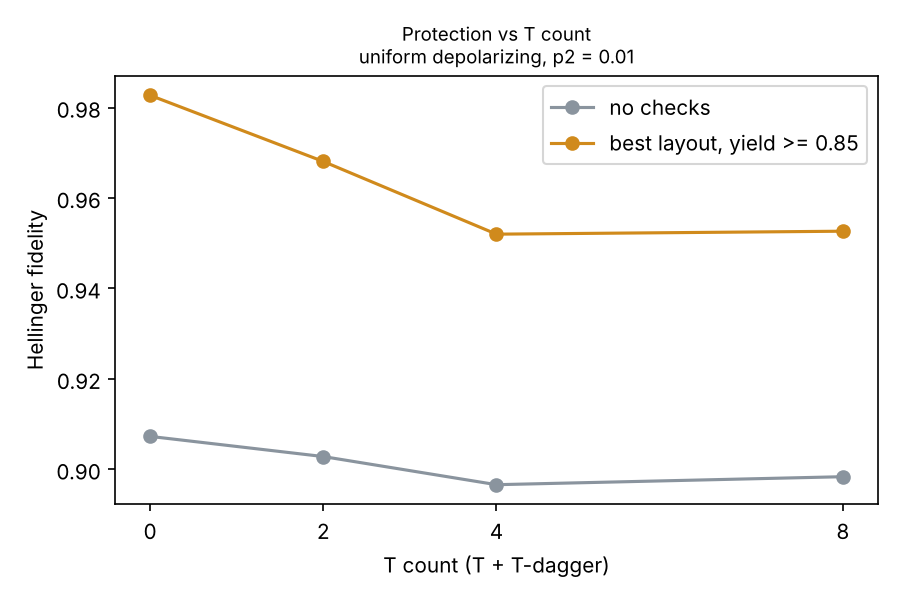

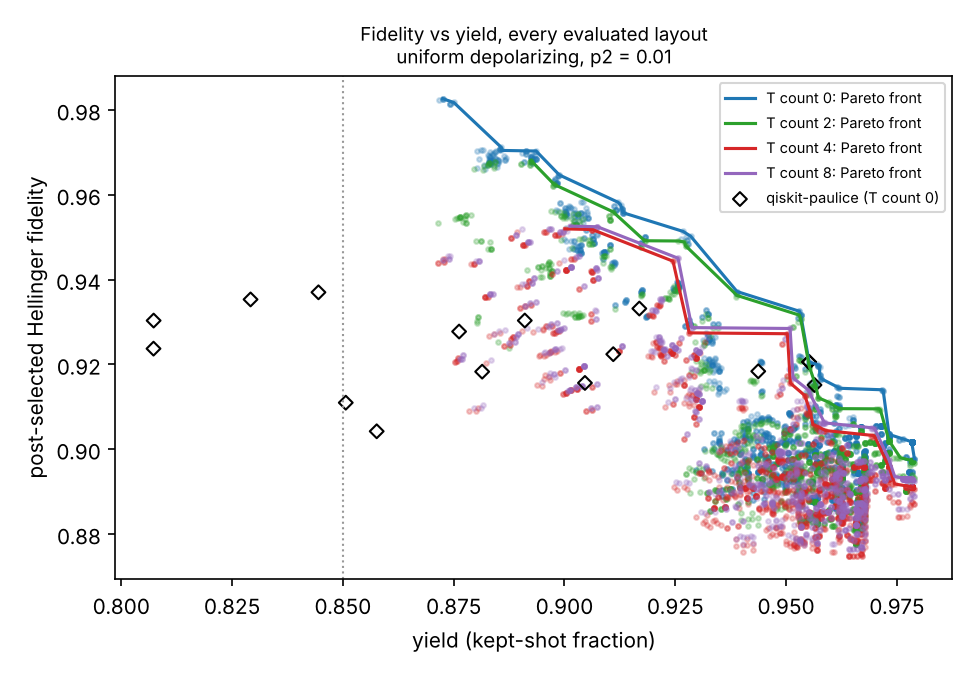

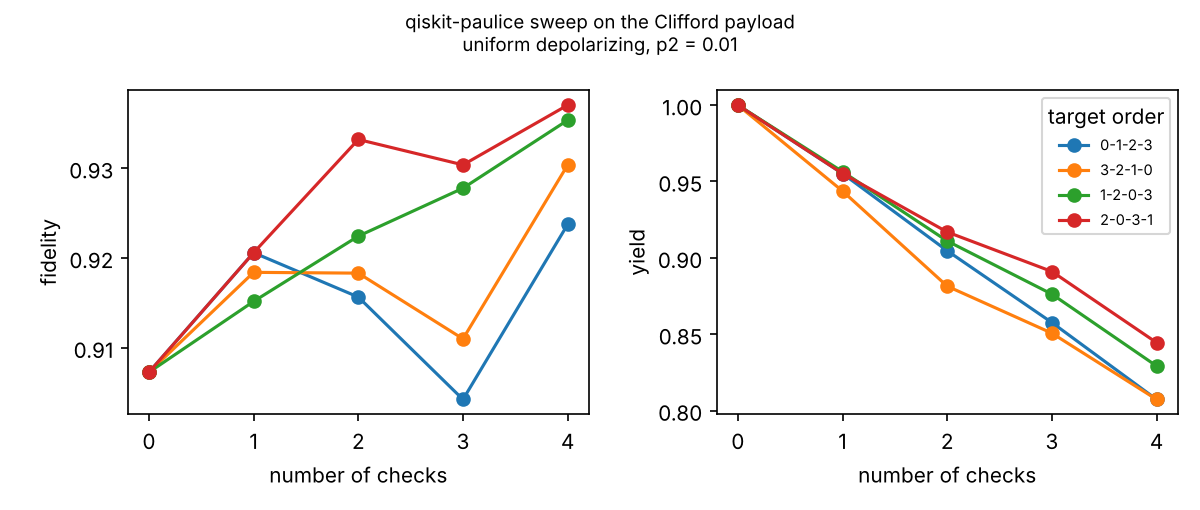

# Brief experiment: GenericBackendV2(12 qubits, seed 2026) calibration, layout [0,1,2,3]

Selection rule for the best trade-off: highest post-selected fidelity with yield >= 0.85, ties broken by lower cost.
All numbers are exact (density matrix, readout applied analytically); no shot sampling.

| T count | width | depth | legal single checks | fidelity, no checks | best (rule) fidelity | its yield | its cost | method | Pareto points |
|---|---|---|---|---|---|---|---|---|---|
| 0 | 4 | 6 | 1760 | 0.9730 | 0.9966 | 0.959 | 6 | hand | 17 |
| 2 | 4 | 8 | 1407 | 0.9659 | 0.9901 | 0.967 | 5 | hand | 12 |
| 4 | 4 | 10 | 1186 | 0.9554 | 0.9820 | 0.944 | 7 | hand | 13 |
| 8 | 4 | 10 | 866 | 0.9619 | 0.9837 | 0.971 | 5 | hand | 15 |

## qiskit-paulice on the Clifford payload (T count 0)

| target order | checks | fidelity | yield | cost |
|---|---|---|---|---|
| 0-1-2-3 | 0 | 0.9730 | 1.000 | 0 |
| 0-1-2-3 | 1 | 0.9746 | 0.984 | 3 |
| 0-1-2-3 | 2 | 0.9635 | 0.953 | 7 |
| 0-1-2-3 | 3 | 0.9480 | 0.918 | 11 |
| 0-1-2-3 | 4 | 0.9622 | 0.885 | 14 |
| 3-2-1-0 | 0 | 0.9730 | 1.000 | 0 |
| 3-2-1-0 | 1 | 0.9629 | 0.977 | 3 |
| 3-2-1-0 | 2 | 0.9459 | 0.939 | 7 |
| 3-2-1-0 | 3 | 0.9382 | 0.919 | 10 |
| 3-2-1-0 | 4 | 0.9608 | 0.885 | 13 |
| 1-2-0-3 | 0 | 0.9730 | 1.000 | 0 |
| 1-2-0-3 | 1 | 0.9683 | 0.987 | 3 |
| 1-2-0-3 | 2 | 0.9648 | 0.968 | 6 |
| 1-2-0-3 | 3 | 0.9672 | 0.954 | 9 |
| 1-2-0-3 | 4 | 0.9643 | 0.922 | 12 |
| 2-0-3-1 | 0 | 0.9730 | 1.000 | 0 |
| 2-0-3-1 | 1 | 0.9757 | 0.983 | 3 |
| 2-0-3-1 | 2 | 0.9833 | 0.969 | 6 |
| 2-0-3-1 | 3 | 0.9823 | 0.960 | 9 |
| 2-0-3-1 | 4 | 0.9786 | 0.933 | 12 |


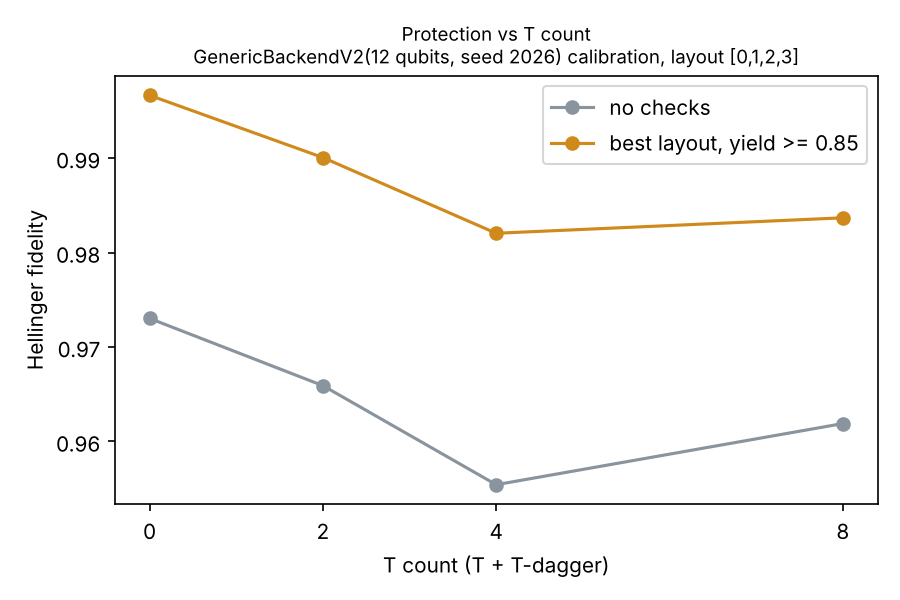

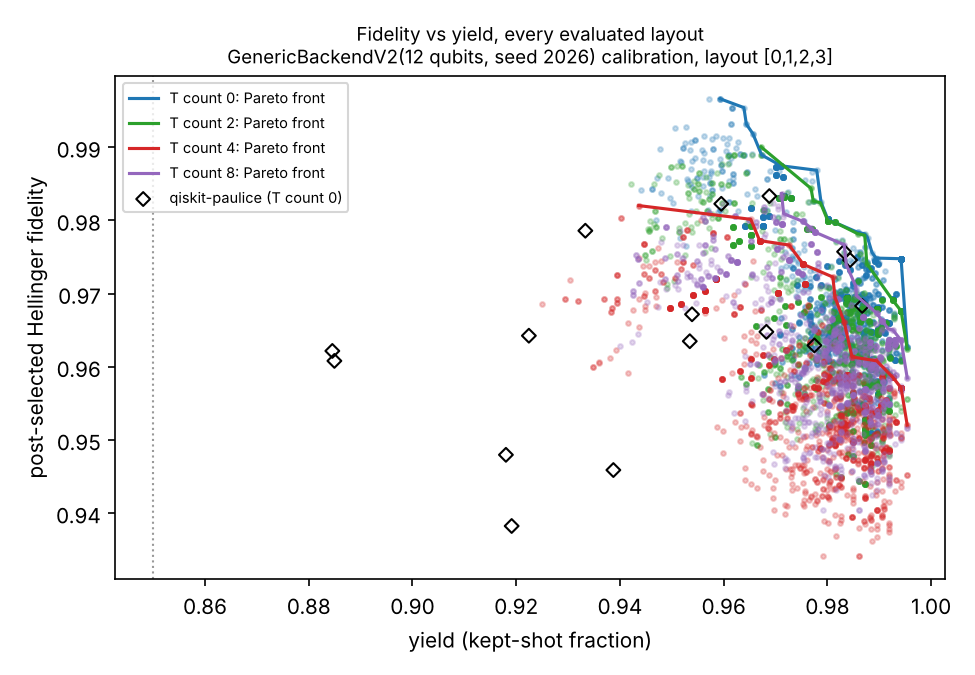

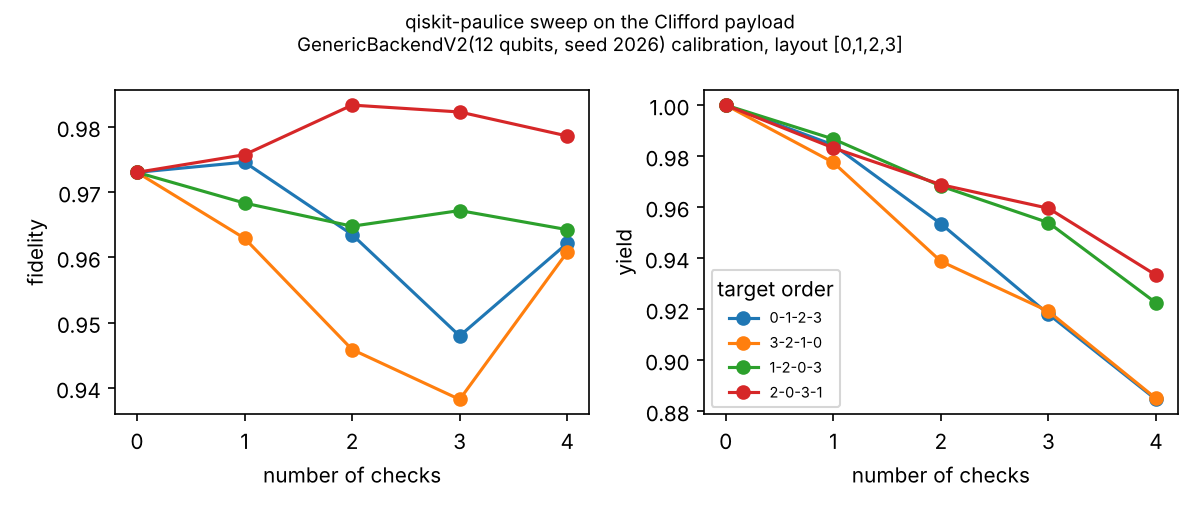

In [4]:
from IPython.display import Markdown, Image, display
for name in models:
    display(Markdown((ROOT / 'experiments' / 'results' / name / 'summary.md').read_text()))
    for img in ['fidelity_vs_tcount.png', 'tradeoff.png', 'paulice_sweep.png']:
        p = ROOT / 'experiments' / 'results' / name / img
        if p.exists():
            display(Image(filename=str(p)))

## Reading the results

* Under the Z-biased series noise, best reachable fidelity falls steadily as T gates are added: each T forbids X-type checks on its qubit, and X-type checks are the only ones that see phase flips.
* Under depolarizing and backend-derived noise the T effect is weaker, because Z-type checks (which survive T gates) still see half of each error. The size of the T penalty depends on the noise bias.
* T counts 4 and 8 share the same depth (their T sites sit in parallel), so part of the 2 to 4 drop is depth, not T count.
* qiskit-paulice optimises its own cost (gamma, the weight of undetectable errors), not post-selected fidelity at a yield floor, and its result depends on the target order. Hand layouts found by the game's search beat it under this selection rule.